In [1]:
# IMPORTING IMPORTANT LIBRARIES
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np 
import math
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error
from keras.models import Sequential
from keras.layers import Dense, Activation
from keras.layers import LSTM
import preprocessor 

2025-12-28 19:56:20.173786: I external/local_xla/xla/tsl/cuda/cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
2025-12-28 19:56:38.574802: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
2025-12-28 19:56:49.483142: I external/local_xla/xla/tsl/cuda/cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
/usr/local/python/3.12.1/lib/python3.12/site-packages/keras/src/export/tf2onnx_lib.py:8: FutureWarning: In the future `np.object` will be defined as the corresponding NumPy scalar.
  if not hasattr(np, "object"):


In [2]:
# FOR REPRODUCIBILITY
np.random.seed(7)

# IMPORTING DATASET 
dataset = pd.read_csv('Intel History Stock Price.csv', usecols=[1,2,3,4])
dataset = dataset.reindex(index = dataset.index[::-1])

# CREATING OWN INDEX FOR FLEXIBILITY
obs = np.arange(1, len(dataset) + 1, 1)

# TAKING DIFFERENT INDICATORS FOR PREDICTION
OHLC_avg = dataset.mean(axis = 1)
#HLC_avg = dataset[['High', 'Low', 'Close']].mean(axis = 1)
#close_val = dataset[['Close']]

# PREPARATION OF TIME SERIES DATASE
OHLC_avg = np.reshape(OHLC_avg, (len(OHLC_avg),1)) 



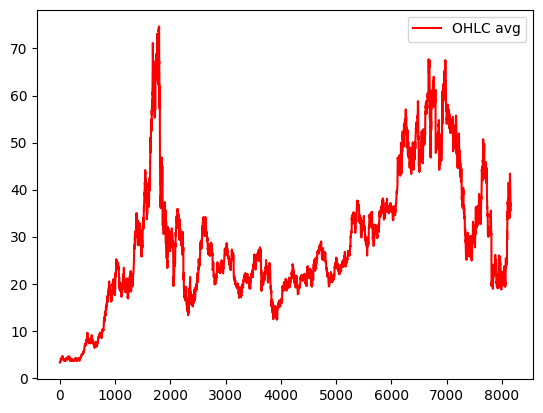

In [3]:
# PLOTTING ALL INDICATORS IN ONE PLOT
plt.plot(obs, OHLC_avg, 'r', label = 'OHLC avg')
#plt.plot(obs, HLC_avg, 'b', label = 'HLC avg')
#plt.plot(obs, close_val, 'g', label = 'Closing price')
plt.legend(loc = 'upper right')
plt.show()


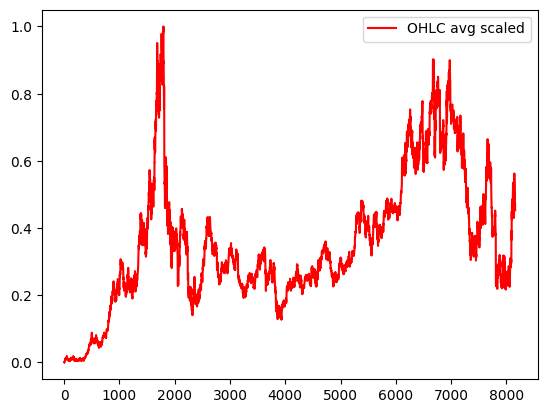

(7336, 1, 7) (7336,) (809, 1, 7) (809,)


In [4]:
# NORMALIZING THE DATASET
scaler = MinMaxScaler(feature_range=(0, 1))
OHLC_avg_scale = scaler.fit_transform(OHLC_avg)
plt.plot(obs, OHLC_avg_scale, 'r', label = 'OHLC avg scaled')
plt.legend(loc = 'upper right')
plt.show()

# TRAIN-TEST SPLIT
train_OHLC = int(len(OHLC_avg_scale) * 0.9)
test_OHLC = len(OHLC_avg_scale) - train_OHLC
train_OHLC, test_OHLC = OHLC_avg_scale[0:train_OHLC,:], OHLC_avg_scale[train_OHLC:len(OHLC_avg_scale),:]

# TIME-SERIES DATASET (FOR TIME T, VALUES FOR TIME T+1)
step_size = 7
trainX, trainY = preprocessor.new_dataset(train_OHLC, step_size)
testX, testY = preprocessor.new_dataset(test_OHLC, step_size)

# RESHAPING TRAIN AND TEST DATA
trainX = np.reshape(trainX, (trainX.shape[0], 1, trainX.shape[1]))
testX = np.reshape(testX, (testX.shape[0], 1, testX.shape[1]))

print(trainX.shape, trainY.shape, testX.shape, testY.shape)



In [5]:
# LSTM MODEL
model = Sequential()
model.add(LSTM(32, input_shape=(1, step_size), return_sequences = True))
model.add(LSTM(16))
model.add(Dense(1))
model.add(Activation('linear'))

# MODEL COMPILING AND TRAINING
model.compile(loss='mean_squared_error', optimizer='adam') # Try SGD, adam, adagrad and compare!!!
model.fit(trainX, trainY, epochs=5, batch_size=1, verbose=2)


2025-12-28 19:57:12.556792: E external/local_xla/xla/stream_executor/cuda/cuda_platform.cc:51] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)
/usr/local/python/3.12.1/lib/python3.12/site-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Epoch 1/5
7336/7336 - 15s - 2ms/step - loss: 0.0013
Epoch 2/5
7336/7336 - 11s - 1ms/step - loss: 2.7766e-04
Epoch 3/5
7336/7336 - 11s - 2ms/step - loss: 2.1348e-04
Epoch 4/5
7336/7336 - 12s - 2ms/step - loss: 1.9632e-04
Epoch 5/5
7336/7336 - 24s - 3ms/step - loss: 1.8210e-04


230/230 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step
26/26 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step 


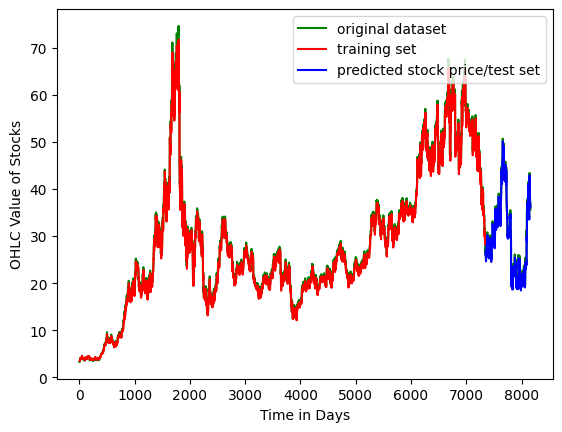

In [58]:
# PREDICTION
trainPredict = model.predict(trainX)
testPredict = model.predict(testX)

# TRAINING RMSE
#trainScore = math.sqrt(mean_squared_error(trainY[0], trainPredict[:,0]))
#print('Train RMSE: %.2f' % (trainScore))

# TEST RMSE
#testScore = math.sqrt(mean_squared_error(testY[0], testPredict[:,0]))
#print('Test RMSE: %.2f' % (testScore))

# DE-NORMALIZING MAIN DATASET 
OHLC_avg_normal = scaler.inverse_transform(OHLC_avg_scale)
# DE-NORMALIZING FOR PLOTTING
trainPredict_normal = scaler.inverse_transform(trainPredict)
trainY_normal = scaler.inverse_transform([trainY])
testPredict_normal = scaler.inverse_transform(testPredict)
testY_normal = scaler.inverse_transform([testY])


# CREATING SIMILAR DATASET TO PLOT TRAINING PREDICTIONS
trainPredictPlot = np.empty_like(OHLC_avg_normal)
trainPredictPlot[:, :] = np.nan
trainPredictPlot[step_size:len(trainPredict_normal)+step_size, :] = trainPredict_normal

# CREATING SIMILAR DATASSET TO PLOT TEST PREDICTIONS
testPredictPlot = np.empty_like(OHLC_avg_normal)
testPredictPlot[:, :] = np.nan
testPredictPlot[len(trainPredict_normal)+(step_size*2)+1:len(OHLC_avg_normal)-1, :] = testPredict_normal

# PLOT OF MAIN OHLC VALUES, TRAIN PREDICTIONS AND TEST PREDICTIONS
plt.plot(OHLC_avg_normal, 'g', label = 'original dataset')
plt.plot(trainPredictPlot, 'r', label = 'training set')
plt.plot(testPredictPlot, 'b', label = 'predicted stock price/test set')
plt.legend(loc = 'upper right')
plt.xlabel('Time in Days')
plt.ylabel('OHLC Value of Stocks')
plt.show()


In [59]:
# PREDICT FUTURE VALUES
last_vals = OHLC_avg[len(OHLC_avg)-step_size:len(OHLC_avg)]
print("Last Day Value:", last_vals)
last_vals_scale = scaler.fit_transform(last_vals)
last_vals_scale = np.reshape(last_vals, (1,1,step_size))
next_val = model.predict(last_vals_scale)
next_val_normal = scaler.inverse_transform(next_val)
print("Next Day Value:", next_val_normal)

Last Day Value: [[37.4425]
 [36.8625]
 [36.705 ]
 [36.83  ]
 [37.1125]
 [36.355 ]
 [35.615 ]]
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step
Next Day Value: [[38.48135]]
